Loading IMDB dataset...
17473536/17464789 [==============================] - 3s 0us/step
Training data shape: (25000, 200)
Test data shape: (25000, 200)
Model: "sequential"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
embedding (Embedding)        (None, 200, 128)          1280000   
_________________________________________________________________
lstm (LSTM)                  (None, 64)                49408     
_________________________________________________________________
dense (Dense)                (None, 32)                2080      
_________________________________________________________________
dropout (Dropout)            (None, 32)                0         
_________________________________________________________________
dense_1 (Dense)              (None, 1)                 33        
Total params: 1,331,521
Trainable params: 1,331,521
Non-trainable params: 0
_________________________

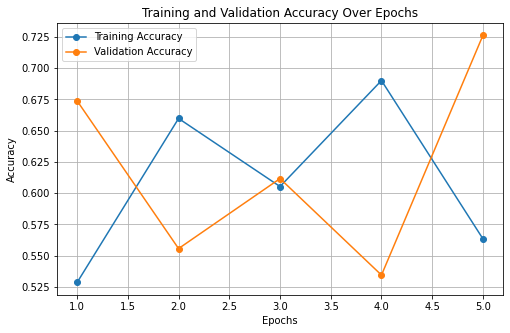

1654784/1641221 [==============================] - 0s 0us/step

Review: "This movie was absolutely wonderful with brilliant acting and a great plot."
Predicted Score: 0.2784
Predicted Sentiment: Negative

Review: "It was a terrible waste of time. The script was horribly written and boring."
Predicted Score: 0.2784
Predicted Sentiment: Negative


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout


tf.random.set_seed(42)
np.random.seed(42)


vocab_size = 10000  
max_length = 200    

print("Loading IMDB dataset...")
(X_train, y_train), (X_test, y_test) = imdb.load_data(num_words=vocab_size)


X_train_padded = pad_sequences(X_train, maxlen=max_length, padding='post', truncating='post')
X_test_padded = pad_sequences(X_test, maxlen=max_length, padding='post', truncating='post')

print(f"Training data shape: {X_train_padded.shape}")
print(f"Test data shape: {X_test_padded.shape}")


embedding_dim = 128

model = Sequential([
    Embedding(input_dim=vocab_size, output_dim=embedding_dim, input_length=max_length),
    LSTM(units=64, dropout=0.2, recurrent_dropout=0.2),
    Dense(units=32, activation='relu'),
    Dropout(0.5),
    Dense(units=1, activation='sigmoid')  # Sigmoid output for binary classification
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()


batch_size = 64
epochs = 5

history = model.fit(
    X_train_padded, y_train,
    epochs=epochs,
    batch_size=batch_size,
    validation_split=0.2,
    verbose=1
)


test_loss, test_acc = model.evaluate(X_test_padded, y_test, verbose=0)
print(f"\nFinal Test Accuracy: {test_acc * 100:.2f}%")


def plot_accuracy(history):
    epochs_range = range(1, len(history.history['accuracy']) + 1)
    
    plt.figure(figsize=(8, 5))
    plt.plot(epochs_range, history.history['accuracy'], label='Training Accuracy', marker='o')
    plt.plot(epochs_range, history.history['val_accuracy'], label='Validation Accuracy', marker='o')
    plt.title('Training and Validation Accuracy Over Epochs')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.grid(True)
    plt.show()

plot_accuracy(history)


word_index = imdb.get_word_index()
# Offset word index by 3 because 0, 1, 2 are reserved for padding, start, and unknown
word_to_id = {k: (v + 3) for k, v in word_index.items()}
word_to_id["<PAD>"] = 0
word_to_id["<START>"] = 1
word_to_id["<UNK>"] = 2

def preprocess_custom_text(text, max_length=200):
    words = text.lower().split()
    sequence = [1]  # Start token
    for word in words:
        sequence.append(word_to_id.get(word, 2))  # Use <UNK> if word is out-of-vocab
    return pad_sequences([sequence], maxlen=max_length, padding='post', truncating='post')

def predict_sentiment(text):
    padded_input = preprocess_custom_text(text, max_length)
    score = model.predict(padded_input, verbose=0)[0][0]
    sentiment = "Positive" if score >= 0.5 else "Negative"
    
    print(f"\nReview: \"{text}\"")
    print(f"Predicted Score: {score:.4f}")
    print(f"Predicted Sentiment: {sentiment}")


predict_sentiment("This movie was absolutely wonderful with brilliant acting and a great plot.")
predict_sentiment("It was a terrible waste of time. The script was horribly written and boring.")

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

# Set random seed for reproducibility
tf.random.set_seed(42)
np.random.seed(42)


In [4]:

# ==========================================
# 1. Load and Preprocess IMDB Dataset
# ==========================================
vocab_size = 10000   # Keep the top 10,000 most frequent words
max_length = 200     # Truncate/Pad sequences to 200 words

print("Loading IMDB dataset...")
(X_train, y_train), (X_test, y_test) = imdb.load_data(num_words=vocab_size)

# Pad sequences to ensure uniform input length
X_train_padded = pad_sequences(X_train, maxlen=max_length, padding='post', truncating='post')
X_test_padded = pad_sequences(X_test, maxlen=max_length, padding='post', truncating='post')

print(f"Training data shape: {X_train_padded.shape}")
print(f"Test data shape: {X_test_padded.shape}")


Loading IMDB dataset...
Training data shape: (25000, 200)
Test data shape: (25000, 200)


In [5]:
# ==========================================
# 2. Build the LSTM Architecture
# ==========================================
embedding_dim = 128

model = Sequential([
    Embedding(input_dim=vocab_size, output_dim=embedding_dim, input_length=max_length),
    LSTM(units=64, dropout=0.2, recurrent_dropout=0.2),
    Dense(units=32, activation='relu'),
    Dropout(0.5),
    Dense(units=1, activation='sigmoid')  # Sigmoid output for binary classification
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()


Model: "sequential_1"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
embedding_1 (Embedding)      (None, 200, 128)          1280000   
_________________________________________________________________
lstm_1 (LSTM)                (None, 64)                49408     
_________________________________________________________________
dense_2 (Dense)              (None, 32)                2080      
_________________________________________________________________
dropout_1 (Dropout)          (None, 32)                0         
_________________________________________________________________
dense_3 (Dense)              (None, 1)                 33        
Total params: 1,331,521
Trainable params: 1,331,521
Non-trainable params: 0
_________________________________________________________________


In [6]:
# ==========================================
# 3. Train the Model
# ==========================================
batch_size = 64
epochs = 5

history = model.fit(
    X_train_padded, y_train,
    epochs=epochs,
    batch_size=batch_size,
    validation_split=0.2,
    verbose=1
)

# Evaluate model performance on test set
test_loss, test_acc = model.evaluate(X_test_padded, y_test, verbose=0)
print(f"\nFinal Test Accuracy: {test_acc * 100:.2f}%")


Epoch 1/5
313/313 [==============================] - 52s 155ms/step - loss: 0.6758 - accuracy: 0.5539 - val_loss: 0.5078 - val_accuracy: 0.7882
Epoch 2/5
313/313 [==============================] - 47s 149ms/step - loss: 0.6654 - accuracy: 0.5700 - val_loss: 0.6753 - val_accuracy: 0.5574
Epoch 3/5
313/313 [==============================] - 47s 149ms/step - loss: 0.6698 - accuracy: 0.5645 - val_loss: 0.6930 - val_accuracy: 0.4974
Epoch 4/5
313/313 [==============================] - 47s 150ms/step - loss: 0.6888 - accuracy: 0.5297 - val_loss: 0.6914 - val_accuracy: 0.5176
Epoch 5/5
313/313 [==============================] - 47s 149ms/step - loss: 0.6840 - accuracy: 0.5543 - val_loss: 0.6937 - val_accuracy: 0.5190

Final Test Accuracy: 51.00%


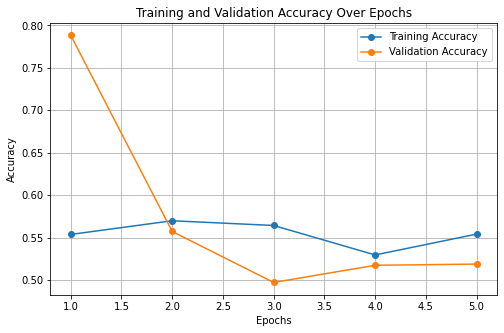

In [7]:
# ==========================================
# 4. Plot Training vs Validation Accuracy
# ==========================================
def plot_accuracy(history):
    epochs_range = range(1, len(history.history['accuracy']) + 1)
    
    plt.figure(figsize=(8, 5))
    plt.plot(epochs_range, history.history['accuracy'], label='Training Accuracy', marker='o')
    plt.plot(epochs_range, history.history['val_accuracy'], label='Validation Accuracy', marker='o')
    plt.title('Training and Validation Accuracy Over Epochs')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.grid(True)
    plt.show()

plot_accuracy(history)


In [8]:
# ==========================================
# 5. Visualize Predictions on Sample Text
# ==========================================
# Get original word index mapping to encode custom reviews
word_index = imdb.get_word_index()
# Offset word index by 3 because 0, 1, 2 are reserved for padding, start, and unknown
word_to_id = {k: (v + 3) for k, v in word_index.items()}
word_to_id["<PAD>"] = 0
word_to_id["<START>"] = 1
word_to_id["<UNK>"] = 2

def preprocess_custom_text(text, max_length=200):
    words = text.lower().split()
    sequence = [1]  # Start token
    for word in words:
        sequence.append(word_to_id.get(word, 2))  # Use <UNK> if word is out-of-vocab
    return pad_sequences([sequence], maxlen=max_length, padding='post', truncating='post')

def predict_sentiment(text):
    padded_input = preprocess_custom_text(text, max_length)
    score = model.predict(padded_input, verbose=0)[0][0]
    sentiment = "Positive" if score >= 0.5 else "Negative"
    
    print(f"\nReview: \"{text}\"")
    print(f"Predicted Score: {score:.4f}")
    print(f"Predicted Sentiment: {sentiment}")

# Example Predictions
predict_sentiment("This movie was absolutely wonderful with brilliant acting and a great plot.")
predict_sentiment("It was a terrible waste of time. The script was horribly written and boring.")


Review: "This movie was absolutely wonderful with brilliant acting and a great plot."
Predicted Score: 0.4325
Predicted Sentiment: Negative

Review: "It was a terrible waste of time. The script was horribly written and boring."
Predicted Score: 0.4325
Predicted Sentiment: Negative
